# Student Performance Prediction

**My goal:** use the information about a student to estimate their math score. I am starting with a simple model and then checking whether a more flexible model does better.

I will use this notebook to practice the ML steps I have learned so far: looking at data, preparing columns, training a model and checking its predictions.

**Dataset:** Students Performance in Exams (download link below). Save the file as `StudentsPerformance.csv` in this folder before running the notebook.

Dataset: https://www.kaggle.com/datasets/spscientist/students-performance-in-exams
Predict a student's **math score** using demographic and academic features.

**Dataset:** Kaggle *Students Performance in Exams* (`StudentsPerformance.csv`).
Download the CSV from https://www.kaggle.com/datasets/spscientist/students-performance-in-exams and place it beside this notebook.

This notebook covers loading data, EDA, preprocessing, a baseline, model comparison, evaluation, and saving the trained pipeline.


In [1]:
# Imports and setup
# I will use these libraries for tables, plots and the ML models below.
# Install dependencies if needed:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path("StudentsPerformance.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError('StudentsPerformance.csv')

df = pd.read_csv(DATA_PATH)
df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [2]:
print("Shape:", df.shape)
display(df.info())
display(df.describe(include="all").T)
print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())


Shape: (1000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,1000,2,female,518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race/ethnicity,1000,5,group C,319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parental level of education,1000,6,some college,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lunch,1000,2,standard,645,NaN,NaN,NaN,NaN,NaN,NaN,NaN
test preparation course,1000,2,none,642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
math score,1000.0,NaN,NaN,NaN,66.089,15.16308,0.0,57.0,66.0,77.0,100.0
reading score,1000.0,NaN,NaN,NaN,69.169,14.600192,17.0,59.0,70.0,79.0,100.0
writing score,1000.0,NaN,NaN,NaN,68.054,15.195657,10.0,57.75,69.0,79.0,100.0


Missing values:
 gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64
Duplicate rows: 0


In [ ]:
# Target: math score. This is a regression task.
target = "math score"
sns.histplot(df[target], kde=True)
plt.title("Distribution of math scores")
plt.show()

plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="test preparation course", y=target)
plt.title("Math score by test preparation course")
plt.xticks(rotation=15)
plt.show()


## Getting the data ready
The value I want to predict is `math score`, so that is my target (`y`). The other columns are the inputs (`X`). Some inputs are words/categories, so I convert those into numeric columns with one-hot encoding. I split the data first so information from the test set does not get used while fitting the preprocessing steps.


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the column we want to predict
target = "math score"

# Separate input features and target
X = df.drop(columns=[target])
y = df[target]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Numeric: ['reading score', 'writing score']
Categorical: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Prepare numerical and categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

print("Preprocessing setup completed!")
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42)
}
results = []
fitted = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })
results_df = pd.DataFrame(results).sort_values("MAE")
results_df


Preprocessing setup completed!


,Model,MAE,RMSE,R2
1,Linear Regression,4.214763,5.393994,0.880433
2,Random Forest,4.638975,5.969945,0.853536
0,Mean baseline,12.339850,15.731647,-0.017039


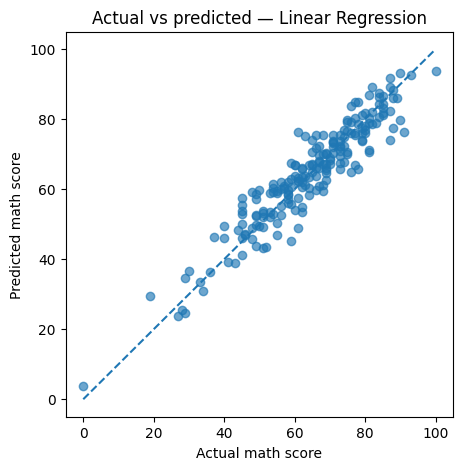

Selected model: Linear Regression
MAE: 4.214763142474848
RMSE: 5.393993869732839
R²: 0.8804332983749567


In [7]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted[best_name]
pred = best_model.predict(X_test)

plt.figure(figsize=(5,5))
plt.scatter(y_test, pred, alpha=0.65)
plt.xlabel("Actual math score")
plt.ylabel("Predicted math score")
plt.title(f"Actual vs predicted — {best_name}")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "--")
plt.show()

print("Selected model:", best_name)
print("MAE:", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R²:", r2_score(y_test, pred))


In [8]:
# Example prediction using one row's feature values.
example = X_test.iloc[[0]]
print("Input row:")
display(example)
print("Predicted math score:", round(float(best_model.predict(example)[0]), 2))
print("Actual math score:", y_test.iloc[0])


Input row:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
521,female,group C,associate's degree,standard,none,86,84


Predicted math score: 76.39
Actual math score: 91


In [9]:
# Save the full preprocessing + model pipeline for later reuse.
import joblib
joblib.dump(best_model, "student_math_score_pipeline.joblib")
print("Saved: student_math_score_pipeline.joblib")


Saved: student_math_score_pipeline.joblib


## What I learned / things to be careful about
- MAE tells me roughly how many score points my predictions are away from the actual scores on average. Smaller is better.
- R² is another way to check the fit, but it is not a percentage accuracy score.
- This is a small practice dataset. A prediction is only an estimate and should not be used to judge a real student.
- Next, I could try cross-validation, test another model, and make a small Streamlit page.
